In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/housing_features.csv")
print(df.shape)
print(df[["Good_Investment"]].value_counts())   # confirms the label is there

(250000, 44)
Good_Investment
1                  127950
0                  122050
Name: count, dtype: int64


### Load and define column groups

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv("../data/processed/housing_features.csv")
print(df.shape, "Future_Price_5Y" in df.columns, "Good_Investment" in df.columns)

ALWAYS_DROP = ["ID", "Amenities", "Locality", "Price_per_SqFt"]       # identifiers, raw text, lakhs-based ratio
LABEL_COLS  = ["Good_Investment", "Rule_Value", "Rule_Infra", "Rule_Amenity",
               "Rule_Age", "Rule_Ready", "Investment_Score"]
REG_COLS    = ["Future_Price_5Y", "Growth_Rate", "City_Growth_Adj",
               "Type_Growth_Adj", "Infra_Growth_Adj"]

# Extra columns to remove for the leakage-free classifier (option A)
LABEL_SOURCES = ["Price_in_Lakhs", "Price_per_SqFt_Rs", "City_Median_Price_per_SqFt",
                 "Price_vs_City_Median", "Infrastructure_Score", "School_Density_Score",
                 "Hospital_Density_Score", "Nearby_Schools", "Nearby_Hospitals",
                 "Public_Transport_Accessibility", "Amenities_Count", "Age_of_Property",
                 "Year_Built", "Age_Group", "Availability_Status"]

(17516, 39) False True


### Features and targets

In [3]:
# Classification
X_clf   = df.drop(columns=ALWAYS_DROP + LABEL_COLS + REG_COLS, errors="ignore")                  # option B
X_clf_A = df.drop(columns=ALWAYS_DROP + LABEL_COLS + REG_COLS + LABEL_SOURCES, errors="ignore")  # option A
y_clf   = df["Good_Investment"]

# Regression (keeps Price_in_Lakhs, since the future price is built from it)
X_reg = df.drop(columns=ALWAYS_DROP + LABEL_COLS + REG_COLS, errors="ignore")
y_reg = df["Future_Price_5Y"]

KeyError: 'Future_Price_5Y'

### Train/test split

In [ ]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)
XcA_train, XcA_test, _, _ = train_test_split(
    X_clf_A, y_clf, test_size=0.2, random_state=42, stratify=y_clf)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)

### Preprocessor (scaling and encoding, fitted on the training data only)

In [ ]:
def make_preprocessor(X):
    num = X.select_dtypes(include="number").columns
    cat = X.select_dtypes(exclude="number").columns
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])

### Imports and metric helpers

In [ ]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, mean_absolute_error, mean_squared_error, r2_score)

def eval_clf(model, X_test, y_test):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
            "ROC_AUC": roc_auc_score(y_test, proba)}

def eval_reg(model, X_test, y_test):
    pred = model.predict(X_test)
    return {"RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "MAE": mean_absolute_error(y_test, pred), "R2": r2_score(y_test, pred)}

### Classification, option B (all features)

In [ ]:
clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
}
fitted_clf, rows = {}, []
for name, m in clf_models.items():
    pipe = Pipeline([("prep", make_preprocessor(Xc_train)), ("model", m)]).fit(Xc_train, yc_train)
    fitted_clf[name] = pipe
    rows.append({"Model": name, **eval_clf(pipe, Xc_test, yc_test)})
pd.DataFrame(rows).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.888,0.891,0.888,0.89,0.963
1,Random Forest,1.000,1.000,1.000,1.00,1.000


### Classification, option A (leakage-free check)

In [ ]:
rows_A = []
for name, m in clf_models.items():
    pipe = Pipeline([("prep", make_preprocessor(XcA_train)), ("model", clone(m))]).fit(XcA_train, yc_train)
    rows_A.append({"Model": name, **eval_clf(pipe, XcA_test, yc_test)})
pd.DataFrame(rows_A).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.583,0.588,0.62,0.604,0.610
1,Random Forest,0.584,0.588,0.63,0.608,0.607


### Regression (Future_Price_5Y)

In [ ]:
reg_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=10,
                                           n_jobs=-1, random_state=42),
}
fitted_reg, rows_R = {}, []
for name, m in reg_models.items():
    pipe = Pipeline([("prep", make_preprocessor(Xr_train)), ("model", m)]).fit(Xr_train, yr_train)
    fitted_reg[name] = pipe
    rows_R.append({"Model": name, **eval_reg(pipe, Xr_test, yr_test)})
pd.DataFrame(rows_R).round(3)

,Model,RMSE,MAE,R2
0,Linear Regression,8.023,5.653,0.999
1,Random Forest,7.482,5.365,0.999


### Feature importance (Random Forest)

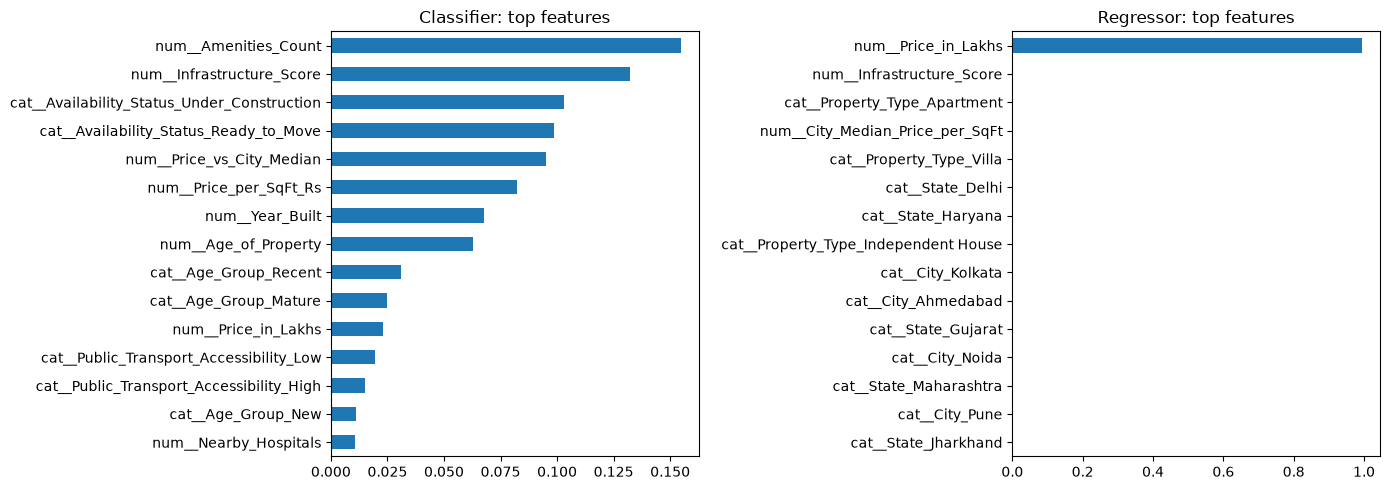

In [ ]:
def top_features(pipe, n=15):
    names = pipe.named_steps["prep"].get_feature_names_out()
    return (pd.Series(pipe.named_steps["model"].feature_importances_, index=names)
              .sort_values(ascending=False).head(n))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
top_features(fitted_clf["Random Forest"]).iloc[::-1].plot(kind="barh", ax=ax[0], title="Classifier: top features")
top_features(fitted_reg["Random Forest"]).iloc[::-1].plot(kind="barh", ax=ax[1], title="Regressor: top features")
plt.tight_layout(); plt.show()